In [5]:
install.packages(c("readxl", "dplyr", "ggplot2", "cluster", "randomForest",
                   "e1071", "pROC", "plotly", "htmlwidgets"))
library(readxl); library(dplyr); library(ggplot2); library(cluster)
library(randomForest); library(e1071); library(pROC); library(plotly)
set.seed(42)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘lazyeval’, ‘proxy’, ‘crosstalk’



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:ggplot2’:

    margin


The following object is masked from ‘package:dplyr’:

    combine



Attaching package: ‘e1071’


The following object is masked from ‘package:ggplot2’:

    element


Type 'citation("pROC")' for a citation.


Attaching package: ‘pROC’


The following objects are masked from ‘package:stats’:

    cov, smooth, var



Attaching package: ‘plotly’


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:

In [6]:
options(HTTPUserAgent = "Mozilla/5.0")
url <- "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
if (!file.exists("Online Retail.xlsx")) {
  download.file(url, "online_retail.zip", mode = "wb")
  unzip("online_retail.zip", exdir = ".")
}
# If the download fails, upload "Online Retail.xlsx" via the Files panel on the left
df <- read_excel("Online Retail.xlsx")
dim(df); head(df); str(df)
colSums(is.na(df))

[1] 541909      8

InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
<chr>,<chr>,<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<chr>
536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850,United Kingdom


tibble [541,909 × 8] (S3: tbl_df/tbl/data.frame)
 $ InvoiceNo  : chr [1:541909] "536365" "536365" "536365" "536365" ...
 $ StockCode  : chr [1:541909] "85123A" "71053" "84406B" "84029G" ...
 $ Description: chr [1:541909] "WHITE HANGING HEART T-LIGHT HOLDER" "WHITE METAL LANTERN" "CREAM CUPID HEARTS COAT HANGER" "KNITTED UNION FLAG HOT WATER BOTTLE" ...
 $ Quantity   : num [1:541909] 6 6 8 6 6 2 6 6 6 32 ...
 $ InvoiceDate: POSIXct[1:541909], format: "2010-12-01 08:26:00" "2010-12-01 08:26:00" ...
 $ UnitPrice  : num [1:541909] 2.55 3.39 2.75 3.39 3.39 7.65 4.25 1.85 1.85 1.69 ...
 $ CustomerID : num [1:541909] 17850 17850 17850 17850 17850 ...
 $ Country    : chr [1:541909] "United Kingdom" "United Kingdom" "United Kingdom" "United Kingdom" ...


InvoiceNo   StockCode Description    Quantity InvoiceDate   UnitPrice 
          0           0        1454           0           0           0 
 CustomerID     Country 
     135080           0

In [7]:
n0 <- nrow(df)
df <- df %>%
  filter(!is.na(CustomerID)) %>%                         # missing customers
  filter(!startsWith(as.character(InvoiceNo), "C")) %>%  # cancellations
  filter(Quantity > 0, UnitPrice > 0) %>%                # invalid rows
  distinct() %>%                                         # duplicates
  mutate(CustomerID = as.integer(CustomerID),
         Revenue = Quantity * UnitPrice)
cat("Retained", round(100 * nrow(df) / n0, 1), "% of rows;",
    n_distinct(df$CustomerID), "unique customers\n")

Retained 72.5 % of rows; 4338 unique customers


In [8]:
snapshot <- max(df$InvoiceDate) + 86400   # last date + 1 day

rfm <- df %>%
  group_by(CustomerID) %>%
  summarise(
    Recency        = floor(as.numeric(difftime(snapshot, max(InvoiceDate), units = "days"))),
    Frequency      = n_distinct(InvoiceNo),
    Monetary       = sum(Revenue),
    TotalQuantity  = sum(Quantity),
    UniqueProducts = n_distinct(StockCode),
    Span           = as.numeric(difftime(max(InvoiceDate), min(InvoiceDate), units = "days")),
    .groups = "drop"
  ) %>%
  mutate(AvgTransactionValue = Monetary / Frequency,
         PurchaseFrequency   = Frequency / pmax(Span / 30, 1))

features <- c("Recency", "Frequency", "Monetary", "AvgTransactionValue",
              "TotalQuantity", "PurchaseFrequency")
summary(rfm[, features])

    Recency         Frequency          Monetary         AvgTransactionValue
 Min.   :  1.00   Min.   :  1.000   Min.   :     3.75   Min.   :    3.45   
 1st Qu.: 18.00   1st Qu.:  1.000   1st Qu.:   306.48   1st Qu.:  177.87   
 Median : 51.00   Median :  2.000   Median :   668.57   Median :  291.94   
 Mean   : 92.54   Mean   :  4.272   Mean   :  2048.69   Mean   :  417.65   
 3rd Qu.:142.00   3rd Qu.:  5.000   3rd Qu.:  1660.60   3rd Qu.:  428.28   
 Max.   :374.00   Max.   :209.000   Max.   :280206.02   Max.   :84236.25   
 TotalQuantity      PurchaseFrequency
 Min.   :     1.0   Min.   : 0.1639  
 1st Qu.:   159.0   1st Qu.: 0.6084  
 Median :   378.0   Median : 1.0000  
 Mean   :  1187.6   Mean   : 1.0366  
 3rd Qu.:   989.8   3rd Qu.: 1.0000  
 Max.   :196915.0   Max.   :34.0000  

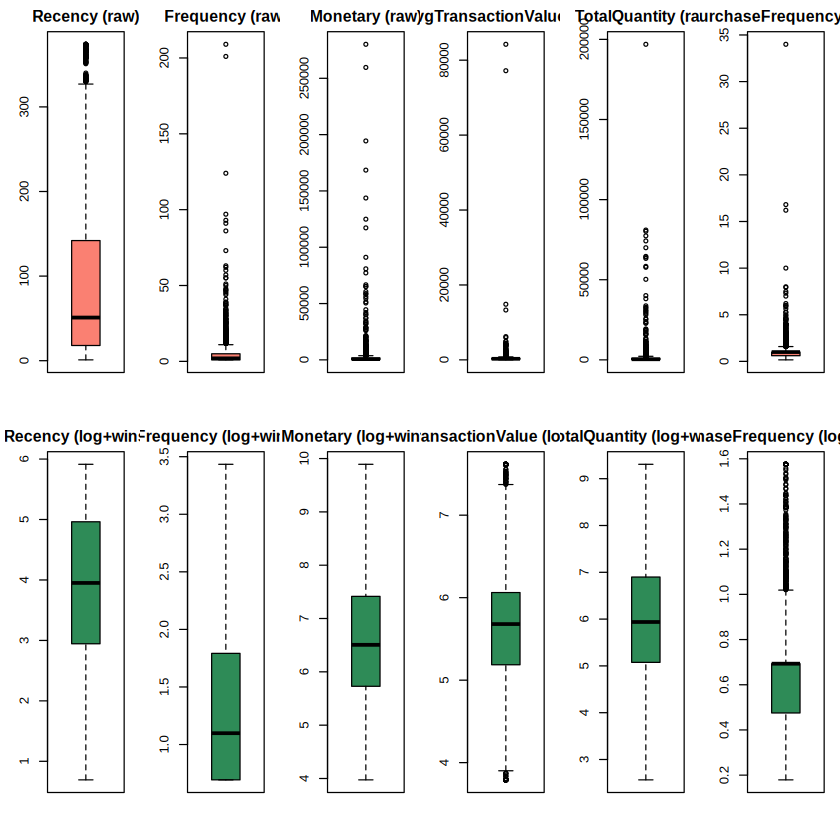

In [9]:
par(mfrow = c(2, 6), mar = c(3, 3, 2, 1))
for (f in features) boxplot(rfm[[f]], main = paste(f, "(raw)"), col = "salmon")

X_log <- log1p(rfm[, features])
winsor <- function(x) { q <- quantile(x, c(0.01, 0.99)); pmin(pmax(x, q[1]), q[2]) }
X_w <- as.data.frame(lapply(X_log, winsor))

for (f in features) boxplot(X_w[[f]], main = paste(f, "(log+winsor)"), col = "seagreen")
par(mfrow = c(1, 1))

X_scaled <- scale(X_w)
d <- dist(X_scaled)

Warning message:
“did not converge in 10 iterations”
Warning message:
“did not converge in 10 iterations”


k,WSS,Silhouette
<int>,<dbl>,<dbl>
2,16377.9,0.327
3,13197.9,0.264
4,11249.3,0.252
5,10003.9,0.241
6,8955.6,0.258
7,8143.3,0.250
8,7619.5,0.247
9,7149.8,0.234
10,6722.6,0.232


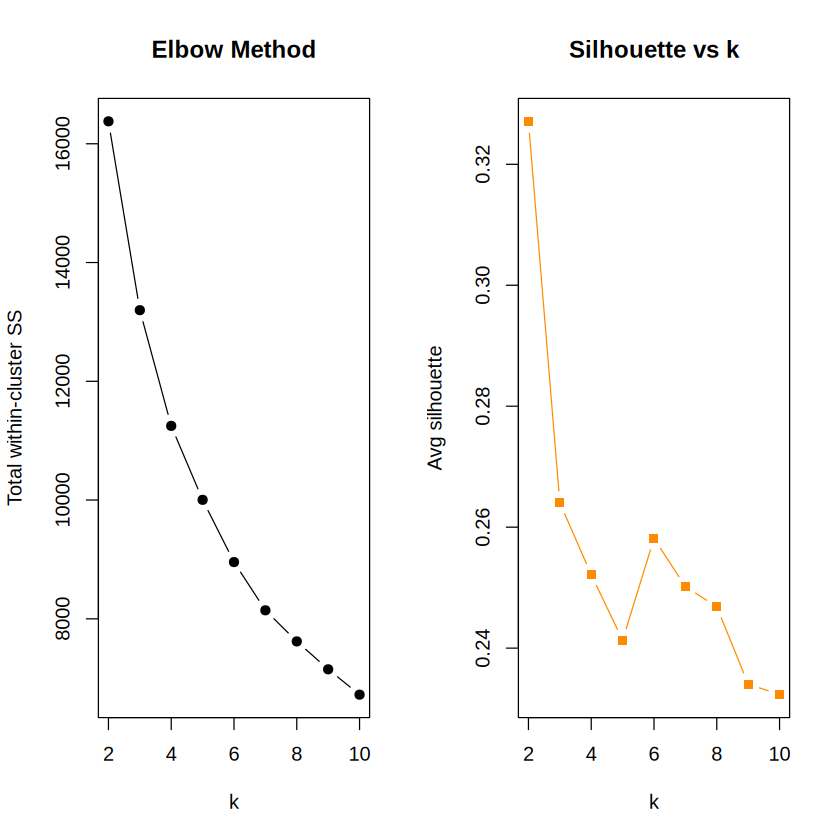

In [10]:
ks <- 2:10
wss <- numeric(length(ks)); sil <- numeric(length(ks))
for (i in seq_along(ks)) {
  km <- kmeans(X_scaled, centers = ks[i], nstart = 25)
  wss[i] <- km$tot.withinss
  sil[i] <- mean(silhouette(km$cluster, d)[, 3])
}
par(mfrow = c(1, 2))
plot(ks, wss, type = "b", pch = 19, xlab = "k", ylab = "Total within-cluster SS", main = "Elbow Method")
plot(ks, sil, type = "b", pch = 15, col = "darkorange", xlab = "k", ylab = "Avg silhouette", main = "Silhouette vs k")
par(mfrow = c(1, 1))
data.frame(k = ks, WSS = round(wss, 1), Silhouette = round(sil, 3))

In [11]:
K_OPT <- 4
km <- kmeans(X_scaled, centers = K_OPT, nstart = 25)
rfm$KMeans <- km$cluster
sil_km <- mean(silhouette(km$cluster, d)[, 3])
cat("K-Means silhouette:", round(sil_km, 3), "\n")
table(rfm$KMeans)

K-Means silhouette: 0.252 



   1    2    3    4 
1105 1154 1378  701 

Hierarchical silhouette: 0.237 


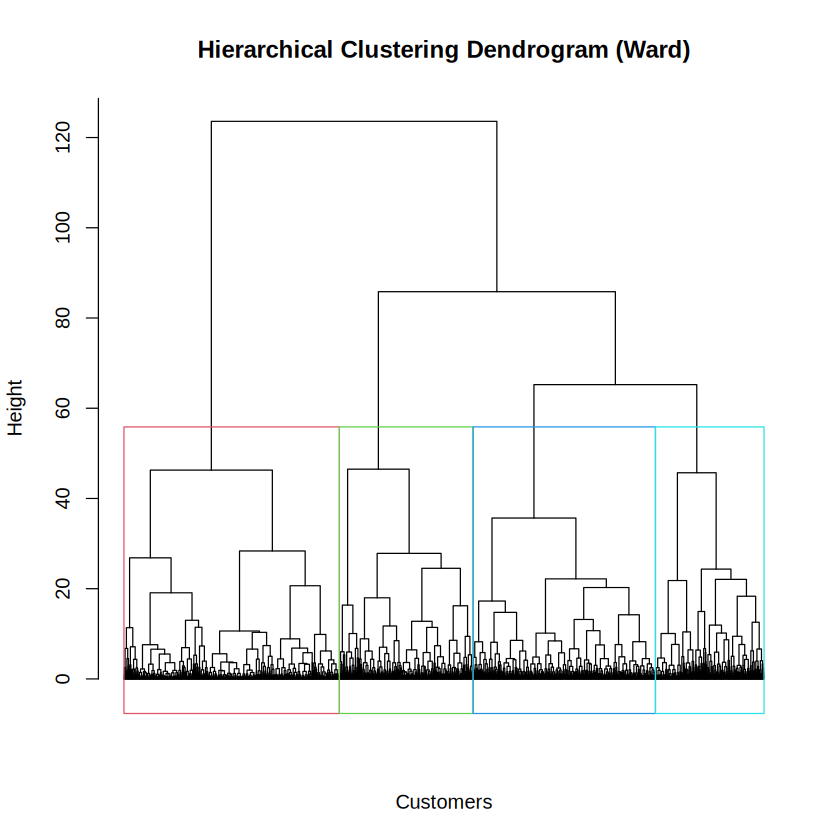

In [12]:
hc <- hclust(d, method = "ward.D2")
plot(hc, labels = FALSE, hang = -1, main = "Hierarchical Clustering Dendrogram (Ward)",
     xlab = "Customers", sub = "")
rect.hclust(hc, k = K_OPT, border = 2:(K_OPT + 1))

rfm$Hier <- cutree(hc, k = K_OPT)
sil_hc <- mean(silhouette(rfm$Hier, d)[, 3])
cat("Hierarchical silhouette:", round(sil_hc, 3), "\n")

In [13]:
ari <- function(a, b) {
  tab <- table(a, b); n <- sum(tab); c2 <- function(x) x * (x - 1) / 2
  sij <- sum(c2(tab)); sa <- sum(c2(rowSums(tab))); sb <- sum(c2(colSums(tab)))
  e <- sa * sb / c2(n)
  (sij - e) / (0.5 * (sa + sb) - e)
}
data.frame(Method = c("K-Means", "Hierarchical (Ward)"),
           Clusters = K_OPT, Silhouette = round(c(sil_km, sil_hc), 3))
cat("Adjusted Rand Index:", round(ari(rfm$KMeans, rfm$Hier), 3), "(1 = identical)\n")
table(KMeans = rfm$KMeans, Hierarchical = rfm$Hier)

Method,Clusters,Silhouette
<chr>,<dbl>,<dbl>
K-Means,4,0.252
Hierarchical (Ward),4,0.237


Adjusted Rand Index: 0.412 (1 = identical)


      Hierarchical
KMeans   1   2   3   4
     1  20   0 179 906
     2 503   7  90 554
     3 112 299 967   0
     4 101 600   0   0

Importance of components:
                          PC1    PC2    PC3     PC4     PC5     PC6
Standard deviation     1.8403 1.0454 0.9683 0.68796 0.32165 0.07806
Proportion of Variance 0.5645 0.1821 0.1563 0.07888 0.01724 0.00102
Cumulative Proportion  0.5645 0.7466 0.9029 0.98174 0.99898 1.00000


,PC1,PC2
Recency,-0.344,-0.367
Frequency,0.457,0.337
Monetary,0.530,-0.122
AvgTransactionValue,0.344,-0.598
TotalQuantity,0.516,-0.117
PurchaseFrequency,0.084,0.604


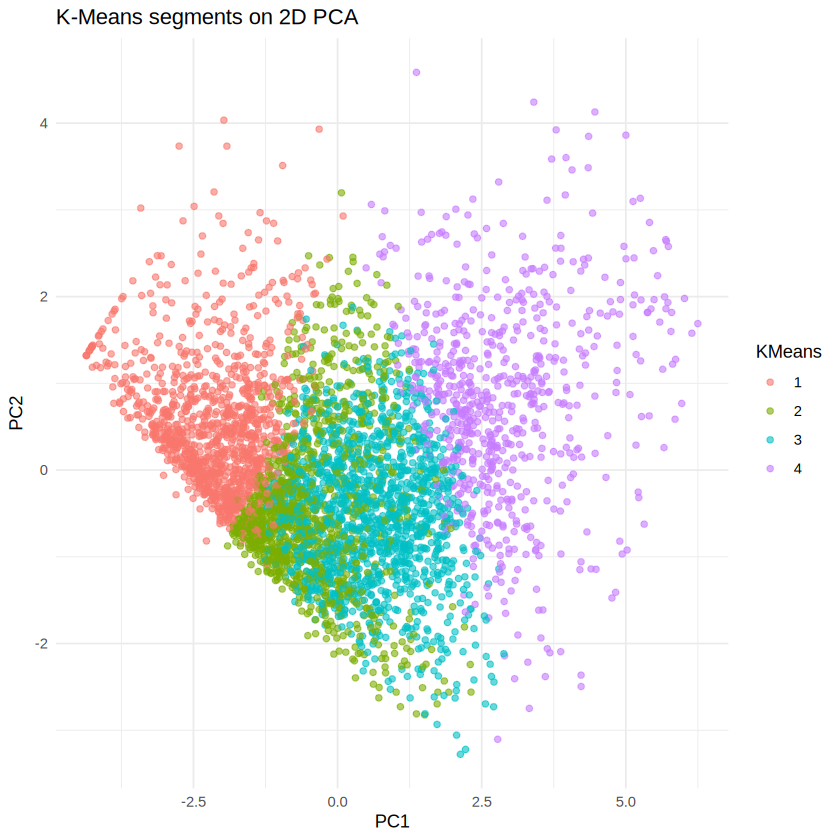

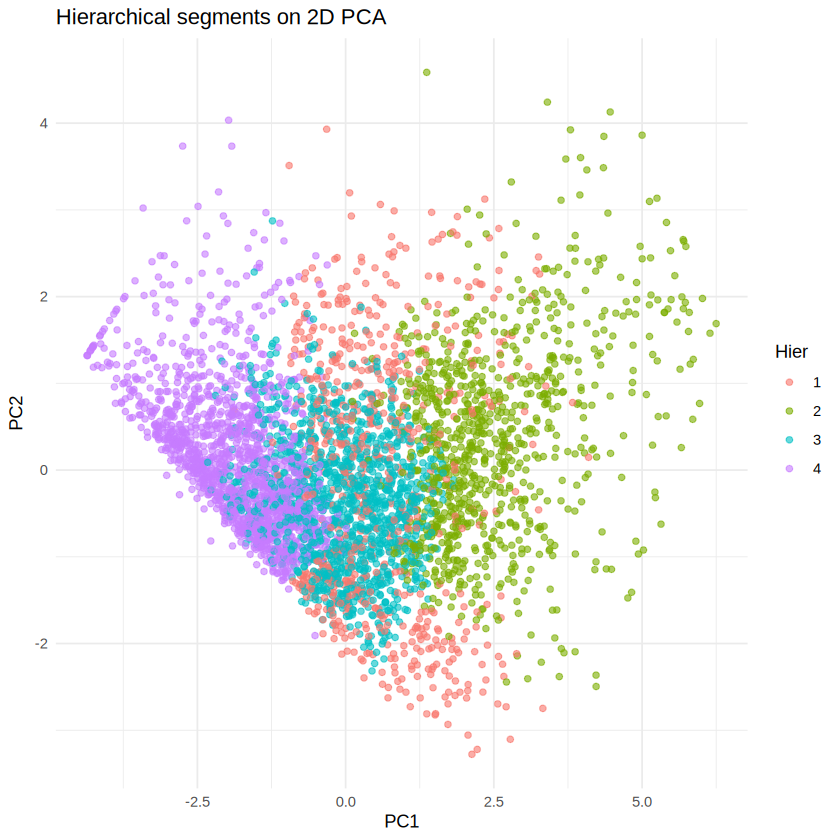

In [14]:
pca <- prcomp(X_scaled)
print(summary(pca))
round(pca$rotation[, 1:2], 3)    # loadings

pc_df <- data.frame(PC1 = pca$x[, 1], PC2 = pca$x[, 2],
                    KMeans = factor(rfm$KMeans), Hier = factor(rfm$Hier))
ggplot(pc_df, aes(PC1, PC2, colour = KMeans)) + geom_point(alpha = 0.6, size = 1.5) +
  theme_minimal() + labs(title = "K-Means segments on 2D PCA")
ggplot(pc_df, aes(PC1, PC2, colour = Hier)) + geom_point(alpha = 0.6, size = 1.5) +
  theme_minimal() + labs(title = "Hierarchical segments on 2D PCA")

In [15]:
profile <- rfm %>%
  group_by(KMeans) %>%
  summarise(Customers = n(), across(all_of(features), ~ round(mean(.x), 1)),
            TotalRev = sum(Monetary), .groups = "drop") %>%
  mutate(PctCustomers = round(100 * Customers / sum(Customers), 1),
         PctRevenue   = round(100 * TotalRev / sum(TotalRev), 1)) %>%
  select(-TotalRev)

label_clusters <- function(p) {
  labels <- setNames(rep(NA_character_, nrow(p)), p$KMeans); rest <- p
  hv <- rest$KMeans[which.max(rest$Monetary)]
  labels[as.character(hv)] <- "Champions (High-Value)"; rest <- rest[rest$KMeans != hv, ]
  if (nrow(rest) > 0) {
    lost <- rest$KMeans[which.max(rest$Recency)]
    labels[as.character(lost)] <- "Lost / Dormant"; rest <- rest[rest$KMeans != lost, ]
  }
  if (nrow(rest) > 0) {
    loy <- rest$KMeans[which.max(rest$Frequency)]
    labels[as.character(loy)] <- "Loyal Customers"; rest <- rest[rest$KMeans != loy, ]
  }
  for (cl in rest$KMeans) labels[as.character(cl)] <- paste0("Occasional / Promising (", cl, ")")
  labels
}
seg_names <- label_clusters(profile)
profile$Segment <- seg_names[as.character(profile$KMeans)]
rfm$Segment <- seg_names[as.character(rfm$KMeans)]
as.data.frame(profile)

KMeans,Customers,Recency,Frequency,Monetary,AvgTransactionValue,TotalQuantity,PurchaseFrequency,PctCustomers,PctRevenue,Segment
<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,1105,153.4,1.5,194.0,143.3,110.2,1.0,25.5,1.8,Lost / Dormant
2,1154,132.6,1.5,721.3,508.6,405.4,1.2,26.6,6.7,Occasional / Promising (2)
3,1378,47.3,4.0,1358.9,362.4,829.3,0.5,31.8,12.6,Loyal Customers
4,701,19.5,13.7,8513.3,809.1,4878.1,1.7,16.2,78.9,Champions (High-Value)


In [16]:
hv_cluster <- profile$KMeans[which.max(profile$Monetary)]
rfm$HighValue <- factor(ifelse(rfm$KMeans == hv_cluster, "Yes", "No"), levels = c("No", "Yes"))
cat("High-value cluster:", hv_cluster, "->", seg_names[as.character(hv_cluster)], "\n")
table(rfm$HighValue)

High-value cluster: 4 -> Champions (High-Value) 



  No  Yes 
3637  701 

In [17]:
model_df <- cbind(X_w, HighValue = rfm$HighValue)

# Stratified 80/20 split
idx <- unlist(lapply(split(seq_len(nrow(model_df)), model_df$HighValue),
                     function(i) sample(i, floor(0.8 * length(i)))))
train <- model_df[idx, ]; test <- model_df[-idx, ]

rf  <- randomForest(HighValue ~ ., data = train, ntree = 300, importance = TRUE)
svm_m <- svm(HighValue ~ ., data = train, kernel = "radial", probability = TRUE)

rf_pred   <- predict(rf, test);  rf_prob  <- predict(rf, test, type = "prob")[, "Yes"]
svm_pred  <- predict(svm_m, test, probability = TRUE)
svm_prob  <- attr(svm_pred, "probabilities")[, "Yes"]

evaluate <- function(truth, pred, prob) {
  pred <- factor(pred, levels = c("No", "Yes"))
  cm <- table(Predicted = pred, Actual = truth)
  TP <- cm["Yes", "Yes"]; TN <- cm["No", "No"]; FP <- cm["Yes", "No"]; FN <- cm["No", "Yes"]
  prec <- TP / (TP + FP); rec <- TP / (TP + FN)
  list(cm = cm,
       metrics = data.frame(Accuracy = (TP + TN) / sum(cm), Precision = prec, Recall = rec,
                            F1 = 2 * prec * rec / (prec + rec),
                            AUC = as.numeric(auc(roc(truth, prob, levels = c("No", "Yes"), quiet = TRUE)))))
}
res_rf  <- evaluate(test$HighValue, rf_pred,  rf_prob)
res_svm <- evaluate(test$HighValue, svm_pred, svm_prob)

results <- rbind("Random Forest" = res_rf$metrics, "SVM (RBF)" = res_svm$metrics)
round(results, 4)

,Accuracy,Precision,Recall,F1,AUC
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Random Forest,0.9919,0.9926,0.9574,0.9747,0.9996
SVM (RBF),0.9965,0.9859,0.9929,0.9894,0.9999


Confusion Matrix - Random Forest
         Actual
Predicted  No Yes
      No  727   6
      Yes   1 135

Confusion Matrix - SVM
         Actual
Predicted  No Yes
      No  726   1
      Yes   2 140


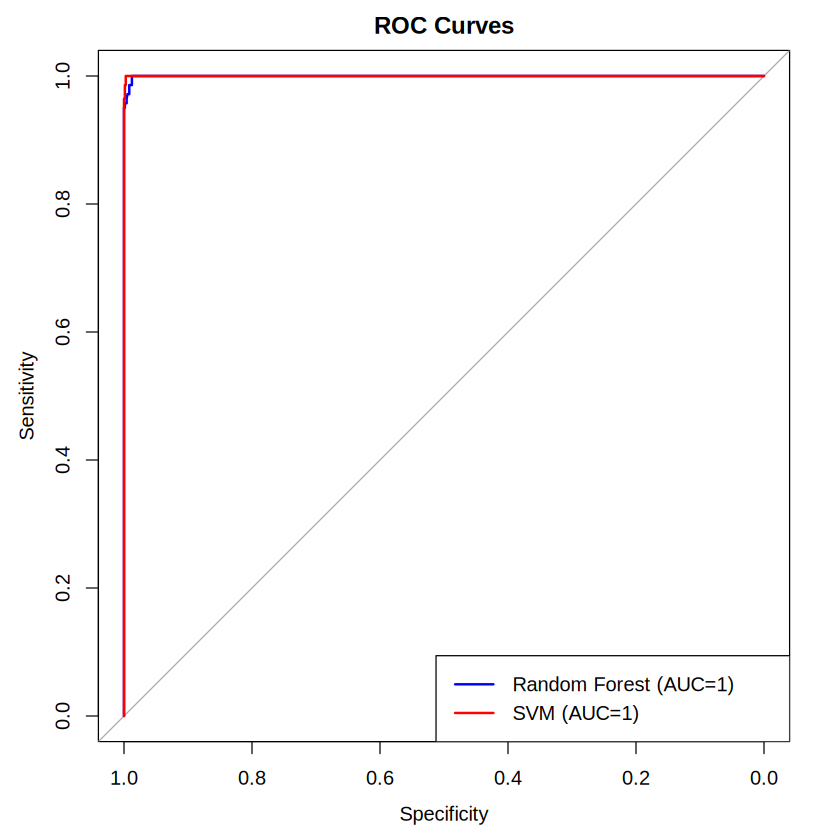

In [18]:
cat("Confusion Matrix - Random Forest\n"); print(res_rf$cm)
cat("\nConfusion Matrix - SVM\n"); print(res_svm$cm)

roc_rf  <- roc(test$HighValue, rf_prob,  levels = c("No", "Yes"), quiet = TRUE)
roc_svm <- roc(test$HighValue, svm_prob, levels = c("No", "Yes"), quiet = TRUE)
plot(roc_rf, col = "blue", lwd = 2, main = "ROC Curves")
lines(roc_svm, col = "red", lwd = 2)
legend("bottomright", lwd = 2, col = c("blue", "red"),
       legend = c(paste0("Random Forest (AUC=", round(auc(roc_rf), 3), ")"),
                  paste0("SVM (AUC=", round(auc(roc_svm), 3), ")")))

In [19]:
# The target comes from clusters built on these same features, so scores above are optimistic.
behav <- c("Recency", "Frequency", "PurchaseFrequency")
rf_b <- randomForest(x = train[, behav], y = train$HighValue, ntree = 300)
pb <- predict(rf_b, test[, behav]); prb <- predict(rf_b, test[, behav], type = "prob")[, "Yes"]
round(evaluate(test$HighValue, pb, prb)$metrics, 3)

Accuracy,Precision,Recall,F1,AUC
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.948,0.887,0.78,0.83,0.982


                        No    Yes MeanDecreaseAccuracy MeanDecreaseGini
Recency             16.666 47.434               45.424           92.071
Frequency           21.391 35.162               36.016          273.107
Monetary            19.232 26.437               30.280          228.499
AvgTransactionValue 14.345  9.727               19.404           32.106
TotalQuantity       14.260 21.514               23.639          176.778
PurchaseFrequency   52.583 35.670               57.935          137.490


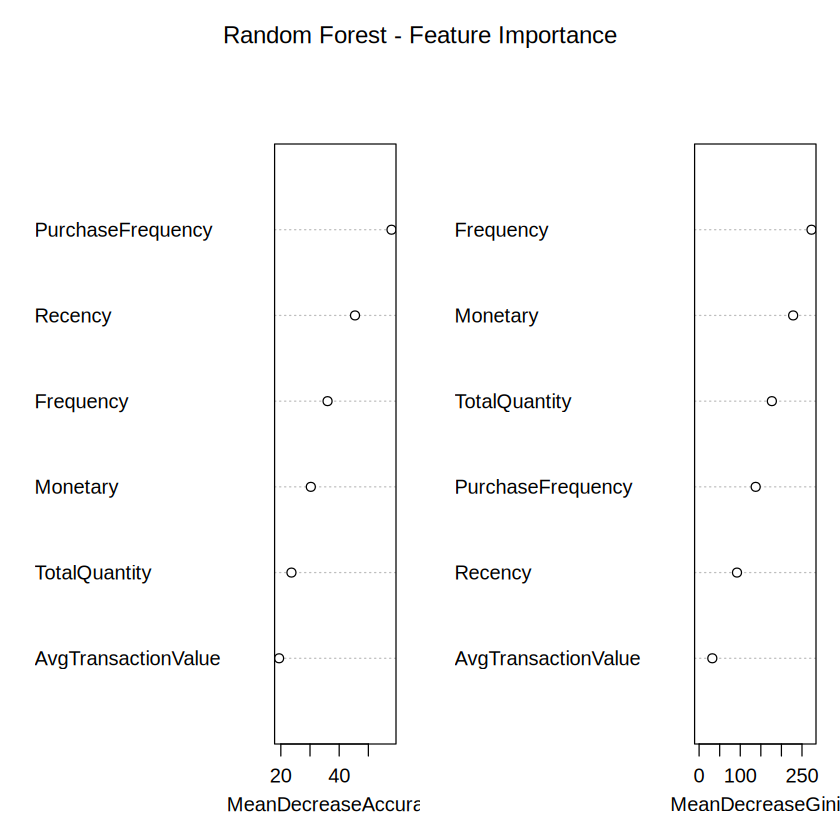

In [20]:
print(round(importance(rf), 3))
varImpPlot(rf, main = "Random Forest - Feature Importance")

In [22]:
strategy <- function(seg) {
  if (startsWith(seg, "Champions")) "VIP/loyalty tier, early access to new products, referral rewards, personal thank-you notes. Avoid heavy discounting."
  else if (startsWith(seg, "Loyal")) "Cross-sell and bundle offers, points-based rewards, subscription/auto-replenish to push them toward Champion level."
  else if (startsWith(seg, "Occasional")) "Welcome/onboarding series, second-purchase incentives, product recommendations, seasonal campaigns to raise frequency."
  else "Win-back emails with time-limited offers, 'we miss you' surveys, low-cost channels only; sunset if no response."
}
rec <- profile[, c("Segment", "Customers", "PctCustomers", "PctRevenue")]
rec$Strategy <- sapply(rec$Segment, strategy)
print(as.data.frame(rec), right = FALSE)

  Segment                    Customers PctCustomers PctRevenue
1 Lost / Dormant             1105      25.5          1.8      
2 Occasional / Promising (2) 1154      26.6          6.7      
3 Loyal Customers            1378      31.8         12.6      
4 Champions (High-Value)      701      16.2         78.9      
  Strategy                                                                                                              
1 Win-back emails with time-limited offers, 'we miss you' surveys, low-cost channels only; sunset if no response.       
2 Welcome/onboarding series, second-purchase incentives, product recommendations, seasonal campaigns to raise frequency.
3 Cross-sell and bundle offers, points-based rewards, subscription/auto-replenish to push them toward Champion level.   
4 VIP/loyalty tier, early access to new products, referral rewards, personal thank-you notes. Avoid heavy discounting.  
